In [ ]:
# Анализ и приведение к стационарности 6 временных рядов

!pip install -q statsmodels

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import warnings
warnings.filterwarnings('ignore')

# Google Диск
from google.colab import drive
drive.mount('/content/drive')

FOLDER_PATH = '/content/drive/MyDrive/Series'

filenames = [
    'daily-total-female-births-in-cal.csv',
    'international-airline-passengers.csv',
    'mean-monthly-air-temperature-deg.csv',
    'monthly-boston-armed-robberies-j.csv',
    'monthly-sales-of-company-x-jan-6.csv',
    'weekly-closings-of-the-dowjones-.csv'
]


Mounted at /content/drive


In [ ]:
# Функция для парсинга дат с поддержкой "год-Wнеделя"

def parse_date_column(series):
    """
    Пытается преобразовать столбец в datetime.
    Если стандартный to_datetime падает с ошибкой, пробует формат "год-Wнеделя"
    и возвращает дату понедельника этой недели.
    """
    try:
        return pd.to_datetime(series)
    except (ValueError, pd.errors.ParserError):
        # Предполагаем формат: "1971-W27"
        # Добавляем "-1" (понедельник) и парсим как "%Y-W%W-%w"
        # Для этого сначала приводим к строке, заменяем "W" на "-W", добавляем "-1"
        def convert(x):
            # x имеет вид "1971-W27"
            # Разделяем по "-W" или "W"?
            import re
            # Удалим лишнее
            x = str(x).strip()
            # Проверим, соответствует ли шаблону
            if re.match(r'^\d{4}-W\d{1,2}$', x):
                # Извлекаем год и неделю
                year, week = x.split('-W')
                # Преобразуем в дату понедельника
                # Используем библиотеку datetime
                from datetime import datetime, timedelta
                # Первый день года
                first_day = datetime(int(year), 1, 1)
                # Находим первый понедельник года (если 1 января - понедельник, то неделя 1)
                # Смещаем до ближайшего понедельника
                days_to_monday = (7 - first_day.weekday()) % 7  # weekday: понедельник=0
                first_monday = first_day + timedelta(days=days_to_monday)
                # Добавляем (неделя-1)*7 дней
                result = first_monday + timedelta(weeks=int(week)-1)
                return result
            else:
                # Если не удалось, пробуем другие варианты (например, если уже дата)
                return pd.to_datetime(x, errors='coerce')
        # Применяем преобразование к каждому элементу
        return pd.Series(series).apply(convert)

In [ ]:
# Вспомогательные функции для тестов и графиков

def adf_test(series, title=''):
    result = adfuller(series, autolag='AIC')
    print(f'ADF тест ({title}):')
    print(f'  ADF Statistic: {result[0]:.4f}')
    print(f'  p-value: {result[1]:.4f}')
    print(f'  Critical values:')
    for key, value in result[4].items():
        print(f'    {key}: {value:.4f}')
    print(f'  Стационарен (p<0.05): {result[1] < 0.05}')
    return result[1] < 0.05

def kpss_test(series, title=''):
    result = kpss(series, regression='c', nlags='auto')
    print(f'KPSS тест ({title}):')
    print(f'  KPSS Statistic: {result[0]:.4f}')
    print(f'  p-value: {result[1]:.4f}')
    print(f'  Critical values:')
    for key, value in result[3].items():
        print(f'    {key}: {value:.4f}')
    print(f'  Стационарен (p>0.05): {result[1] > 0.05}')
    return result[1] > 0.05

def check_stationarity(series, title=''):
    print(f'\n=== Проверка стационарности: {title} ===')
    is_adf = adf_test(series, title)
    is_kpss = kpss_test(series, title)
    if is_adf and is_kpss:
        print('✅ Ряд стационарен (по обоим тестам).')
    elif is_adf and not is_kpss:
        print('⚠️ Противоречие: ADF говорит о стационарности, KPSS – о нестационарности.')
    elif not is_adf and is_kpss:
        print('⚠️ Противоречие: ADF говорит о нестационарности, KPSS – о стационарности.')
    else:
        print('❌ Ряд нестационарен (по обоим тестам).')
    return is_adf and is_kpss

def plot_series(series, title='', acf=True, pacf=True):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    series.plot(ax=axes[0], title=f'{title} - исходный ряд')
    axes[0].set_xlabel('Время')
    if acf:
        plot_acf(series, ax=axes[1], lags=min(40, len(series)//2-1))
        axes[1].set_title('ACF')
    if pacf:
        plot_pacf(series, ax=axes[2], lags=min(40, len(series)//2-1), method='ywm')
        axes[2].set_title('PACF')
    plt.tight_layout()
    plt.show()

def make_stationary(series, title='', season_period=None, log_transform=False):
    transformed = series.copy()
    transformations = []

    if log_transform and (transformed > 0).all():
        transformed = np.log(transformed)
        transformations.append('log')
        print(f'  Применено логарифмирование.')

    d = 0
    while True:
        is_adf = adfuller(transformed, autolag='AIC')[1] < 0.05
        is_kpss = kpss(transformed, regression='c', nlags='auto')[1] > 0.05
        if is_adf and is_kpss:
            break
        transformed = transformed.diff().dropna()
        d += 1
        transformations.append(f'diff_{d}')
        print(f'  Применено обычное дифференцирование (порядок {d}).')
        if len(transformed) < 10:
            print('  Ряд слишком короткий, остановка.')
            break

    if season_period is not None and len(transformed) > season_period:
        trans_temp = transformed.copy()
        trans_season = trans_temp.diff(season_period).dropna()
        if len(trans_season) > 0:
            p_adf_season = adfuller(trans_season, autolag='AIC')[1]
            p_adf_orig = adfuller(trans_temp, autolag='AIC')[1]
            if p_adf_season < p_adf_orig:
                transformed = trans_season
                transformations.append(f'seasonal_diff_{season_period}')
                print(f'  Применено сезонное дифференцирование с периодом {season_period}.')
                while True:
                    is_adf = adfuller(transformed, autolag='AIC')[1] < 0.05
                    is_kpss = kpss(transformed, regression='c', nlags='auto')[1] > 0.05
                    if is_adf and is_kpss:
                        break
                    transformed = transformed.diff().dropna()
                    d += 1
                    transformations.append(f'diff_{d}')
                    print(f'  Дополнительное обычное дифференцирование (порядок {d}).')
                    if len(transformed) < 10:
                        break

    return transformed, transformations

✅ Папка найдена: /content/drive/MyDrive/Series

Обработка файла: daily-total-female-births-in-cal.csv
Столбцы в файле: ['Date', 'Count']
Столбец даты: 'Date', столбец значений: 'Count'
Длина ряда: 365


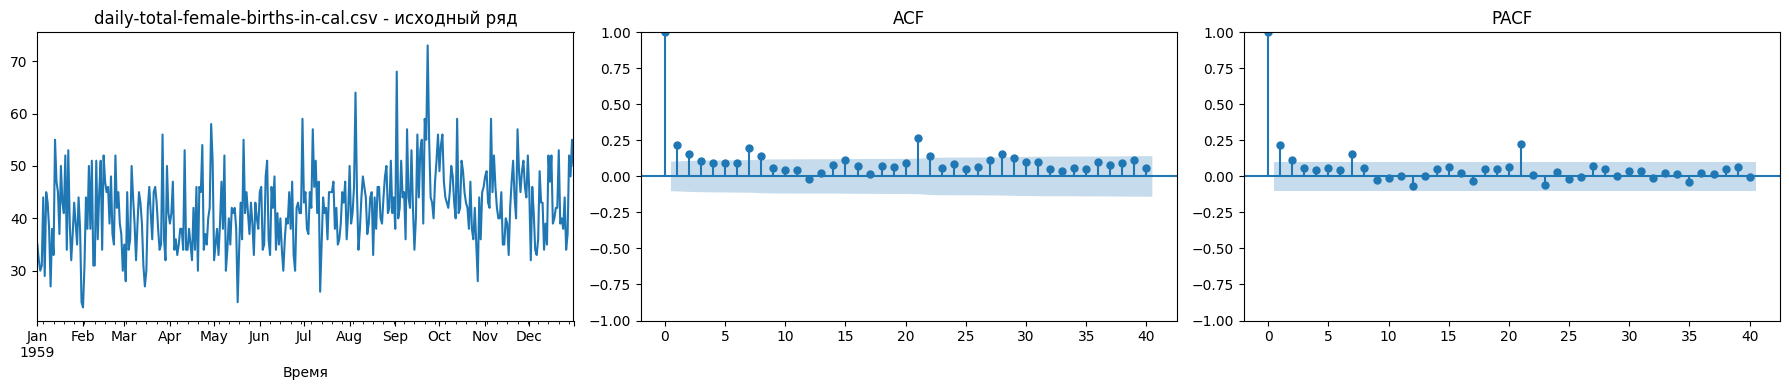


=== Проверка стационарности: Исходный ряд ===
ADF тест (Исходный ряд):
  ADF Statistic: -4.8083
  p-value: 0.0001
  Critical values:
    1%: -3.4487
    5%: -2.8696
    10%: -2.5711
  Стационарен (p<0.05): True
KPSS тест (Исходный ряд):
  KPSS Statistic: 1.6130
  p-value: 0.0100
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): False
⚠️ Противоречие: ADF говорит о стационарности, KPSS – о нестационарности.

--- Применение преобразований для достижения стационарности ---
  Применено обычное дифференцирование (порядок 1).
Применённые преобразования: ['diff_1']


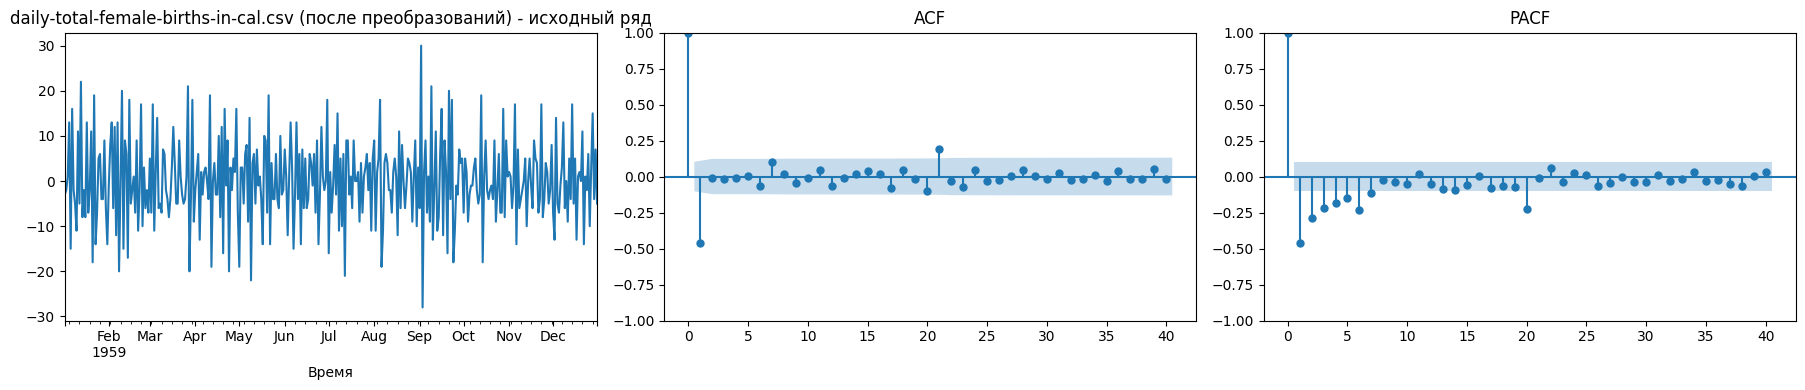


=== Проверка стационарности: После преобразований ===
ADF тест (После преобразований):
  ADF Statistic: -12.6252
  p-value: 0.0000
  Critical values:
    1%: -3.4488
    5%: -2.8697
    10%: -2.5711
  Стационарен (p<0.05): True
KPSS тест (После преобразований):
  KPSS Statistic: 0.1874
  p-value: 0.1000
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): True
✅ Ряд стационарен (по обоим тестам).
✅ Ряд успешно приведён к стационарности.

------------------------------------------------------------

Обработка файла: international-airline-passengers.csv
Столбцы в файле: ['Month', 'Count']
Столбец даты: 'Month', столбец значений: 'Count'
Длина ряда: 144


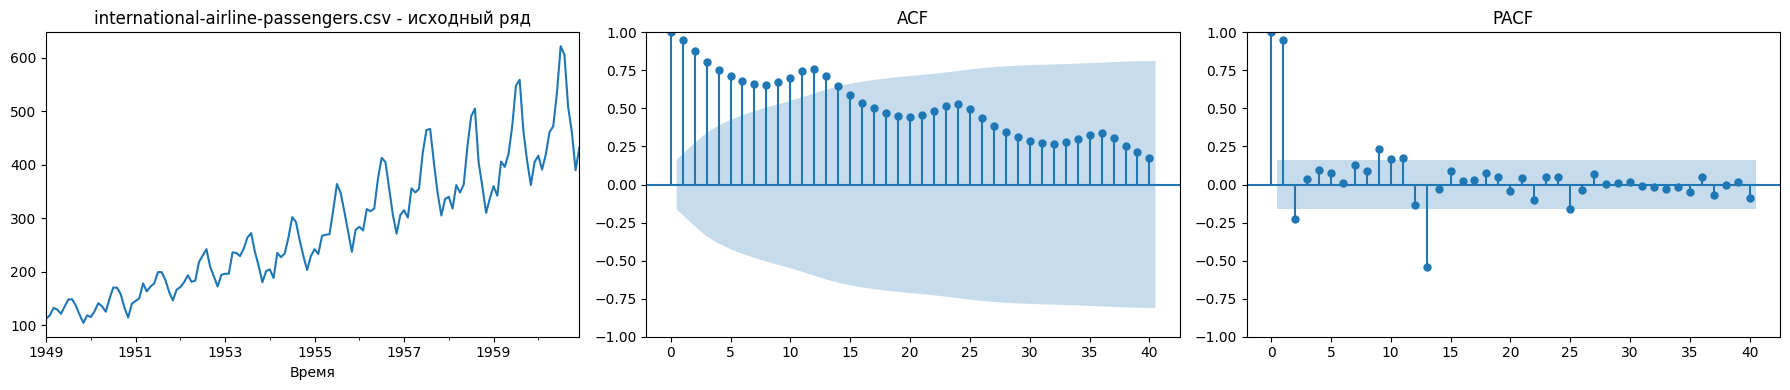


=== Проверка стационарности: Исходный ряд ===
ADF тест (Исходный ряд):
  ADF Statistic: 0.8154
  p-value: 0.9919
  Critical values:
    1%: -3.4817
    5%: -2.8840
    10%: -2.5788
  Стационарен (p<0.05): False
KPSS тест (Исходный ряд):
  KPSS Statistic: 1.6513
  p-value: 0.0100
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): False
❌ Ряд нестационарен (по обоим тестам).

--- Применение преобразований для достижения стационарности ---
  Применено логарифмирование.
  Применено обычное дифференцирование (порядок 1).
  Применено обычное дифференцирование (порядок 2).
Применённые преобразования: ['log', 'diff_1', 'diff_2']


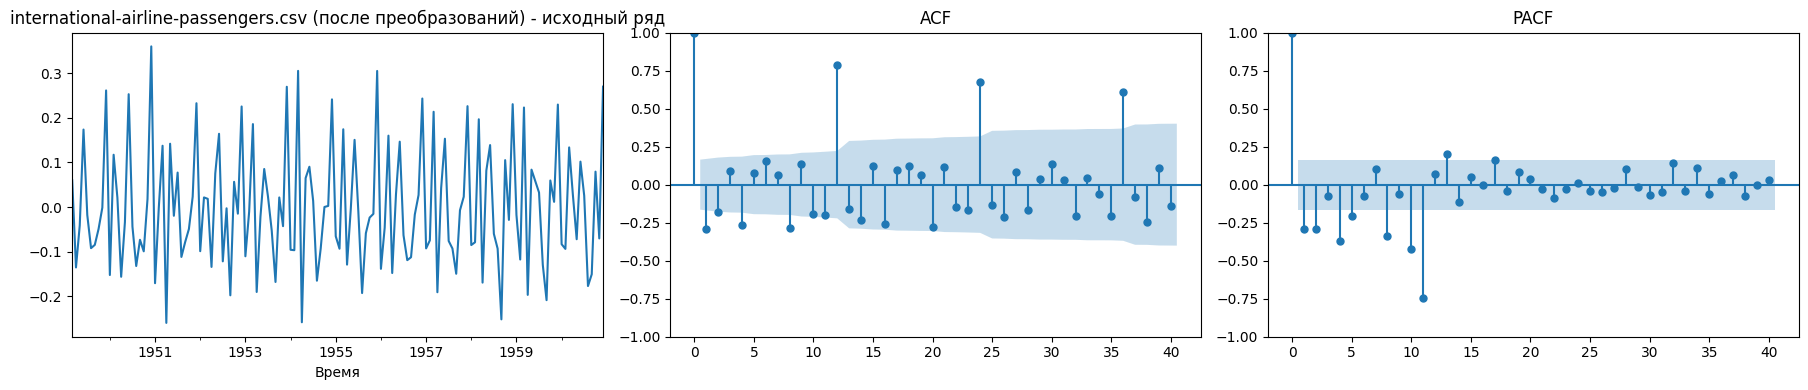


=== Проверка стационарности: После преобразований ===
ADF тест (После преобразований):
  ADF Statistic: -8.1966
  p-value: 0.0000
  Critical values:
    1%: -3.4825
    5%: -2.8844
    10%: -2.5790
  Стационарен (p<0.05): True
KPSS тест (После преобразований):
  KPSS Statistic: 0.0596
  p-value: 0.1000
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): True
✅ Ряд стационарен (по обоим тестам).
✅ Ряд успешно приведён к стационарности.

------------------------------------------------------------

Обработка файла: mean-monthly-air-temperature-deg.csv
Столбцы в файле: ['Month', 'Deg']
Столбец даты: 'Month', столбец значений: 'Deg'
Длина ряда: 240


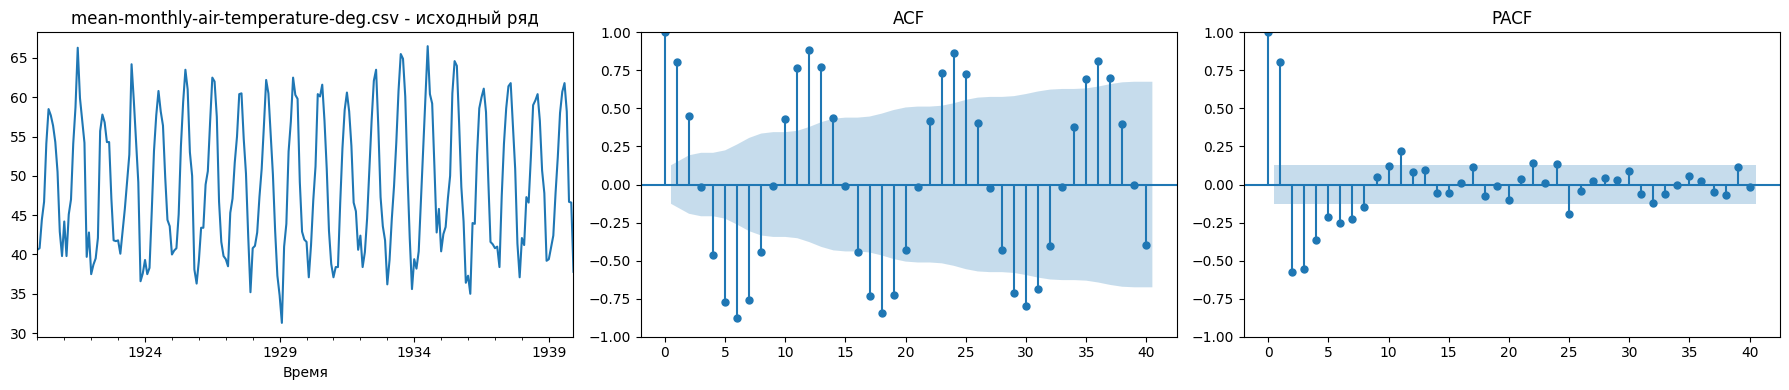


=== Проверка стационарности: Исходный ряд ===
ADF тест (Исходный ряд):
  ADF Statistic: -3.2555
  p-value: 0.0170
  Critical values:
    1%: -3.4598
    5%: -2.8745
    10%: -2.5737
  Стационарен (p<0.05): True
KPSS тест (Исходный ряд):
  KPSS Statistic: 0.0439
  p-value: 0.1000
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): True
✅ Ряд стационарен (по обоим тестам).

--- Применение преобразований для достижения стационарности ---
  Применено сезонное дифференцирование с периодом 12.
Применённые преобразования: ['seasonal_diff_12']


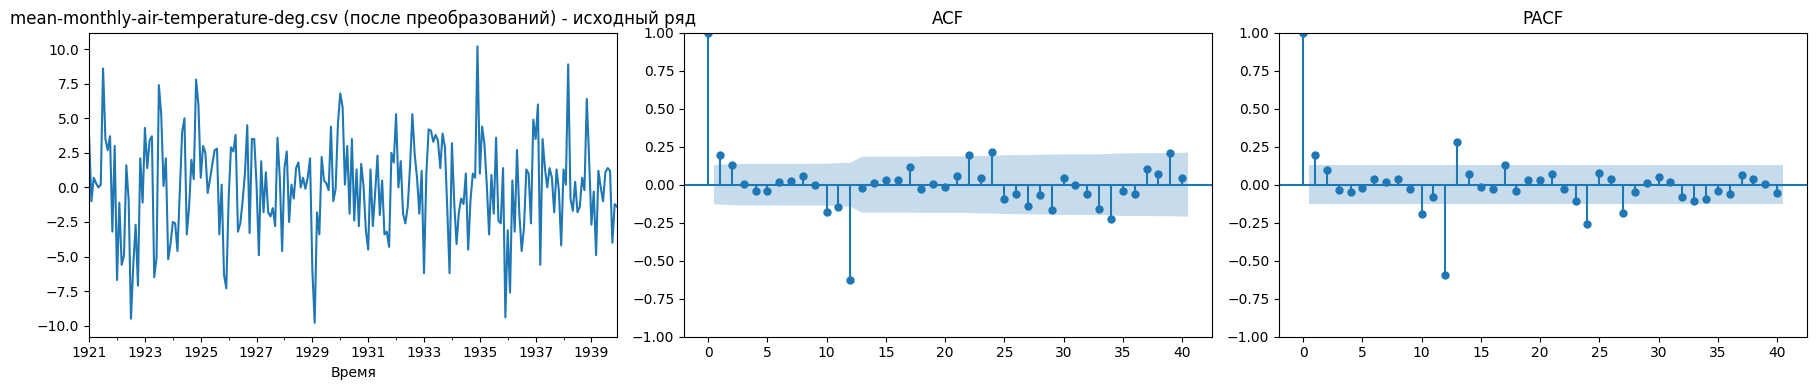


=== Проверка стационарности: После преобразований ===
ADF тест (После преобразований):
  ADF Statistic: -6.0725
  p-value: 0.0000
  Critical values:
    1%: -3.4611
    5%: -2.8751
    10%: -2.5740
  Стационарен (p<0.05): True
KPSS тест (После преобразований):
  KPSS Statistic: 0.0268
  p-value: 0.1000
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): True
✅ Ряд стационарен (по обоим тестам).
✅ Ряд успешно приведён к стационарности.

------------------------------------------------------------

Обработка файла: monthly-boston-armed-robberies-j.csv
Столбцы в файле: ['Month', 'Count']
Столбец даты: 'Month', столбец значений: 'Count'
Длина ряда: 118


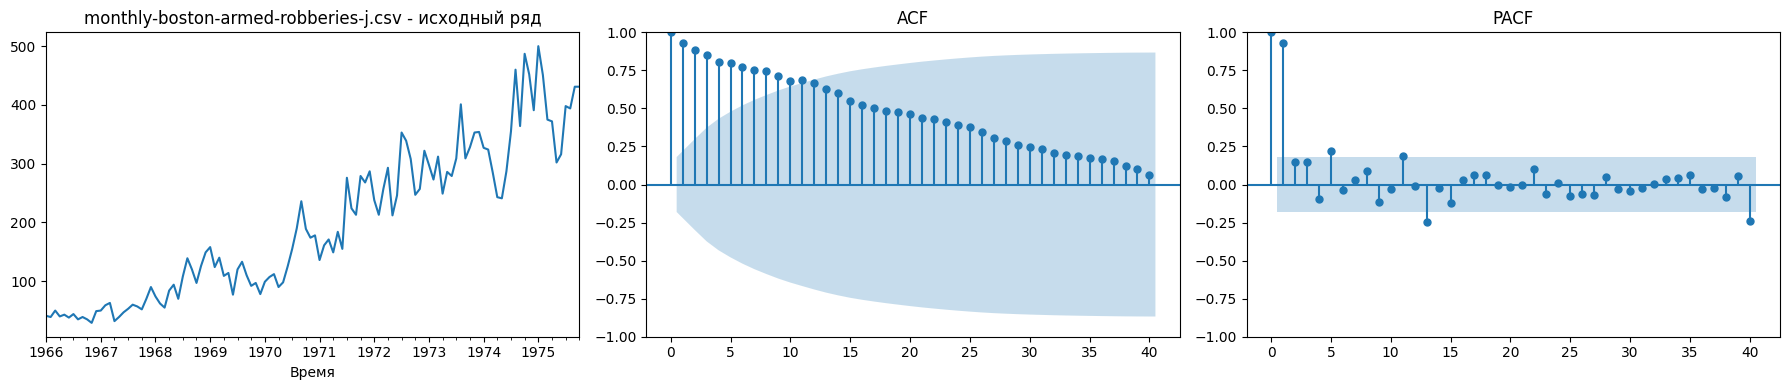


=== Проверка стационарности: Исходный ряд ===
ADF тест (Исходный ряд):
  ADF Statistic: 1.0011
  p-value: 0.9943
  Critical values:
    1%: -3.4936
    5%: -2.8892
    10%: -2.5815
  Стационарен (p<0.05): False
KPSS тест (Исходный ряд):
  KPSS Statistic: 1.7119
  p-value: 0.0100
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): False
❌ Ряд нестационарен (по обоим тестам).

--- Применение преобразований для достижения стационарности ---
  Применено обычное дифференцирование (порядок 1).
Применённые преобразования: ['diff_1']


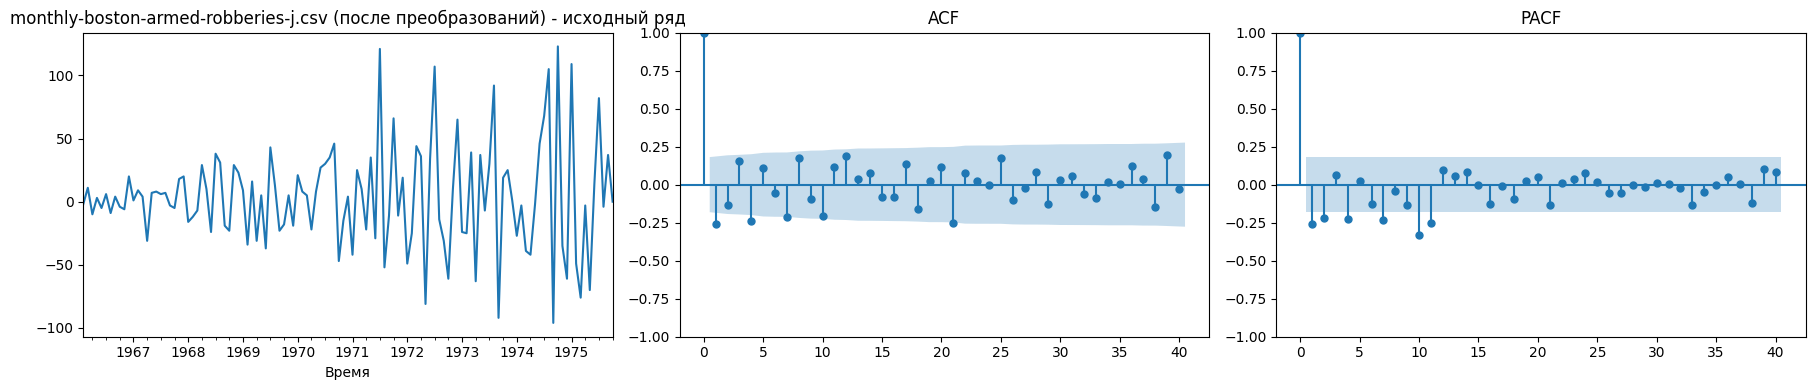


=== Проверка стационарности: После преобразований ===
ADF тест (После преобразований):
  ADF Statistic: -7.4286
  p-value: 0.0000
  Critical values:
    1%: -3.4936
    5%: -2.8892
    10%: -2.5815
  Стационарен (p<0.05): True
KPSS тест (После преобразований):
  KPSS Statistic: 0.1316
  p-value: 0.1000
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): True
✅ Ряд стационарен (по обоим тестам).
✅ Ряд успешно приведён к стационарности.

------------------------------------------------------------

Обработка файла: monthly-sales-of-company-x-jan-6.csv
Столбцы в файле: ['Month', 'Count']
Столбец даты: 'Month', столбец значений: 'Count'
Длина ряда: 77


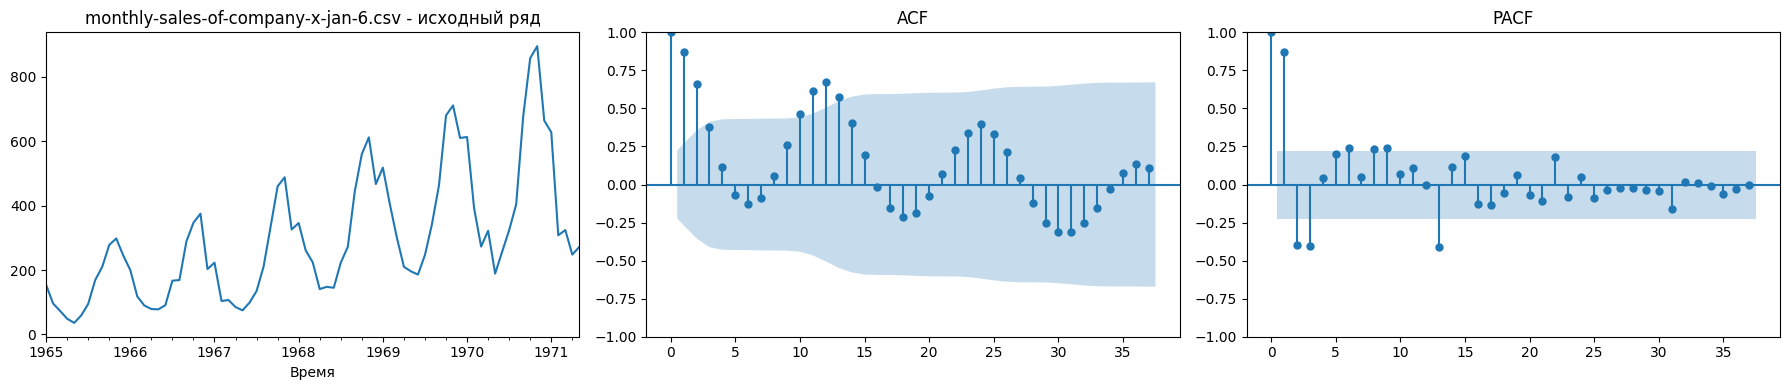


=== Проверка стационарности: Исходный ряд ===
ADF тест (Исходный ряд):
  ADF Statistic: 0.6547
  p-value: 0.9889
  Critical values:
    1%: -3.5369
    5%: -2.9079
    10%: -2.5915
  Стационарен (p<0.05): False
KPSS тест (Исходный ряд):
  KPSS Statistic: 0.8524
  p-value: 0.0100
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): False
❌ Ряд нестационарен (по обоим тестам).

--- Применение преобразований для достижения стационарности ---
  Применено логарифмирование.
  Применено обычное дифференцирование (порядок 1).
Применённые преобразования: ['log', 'diff_1']


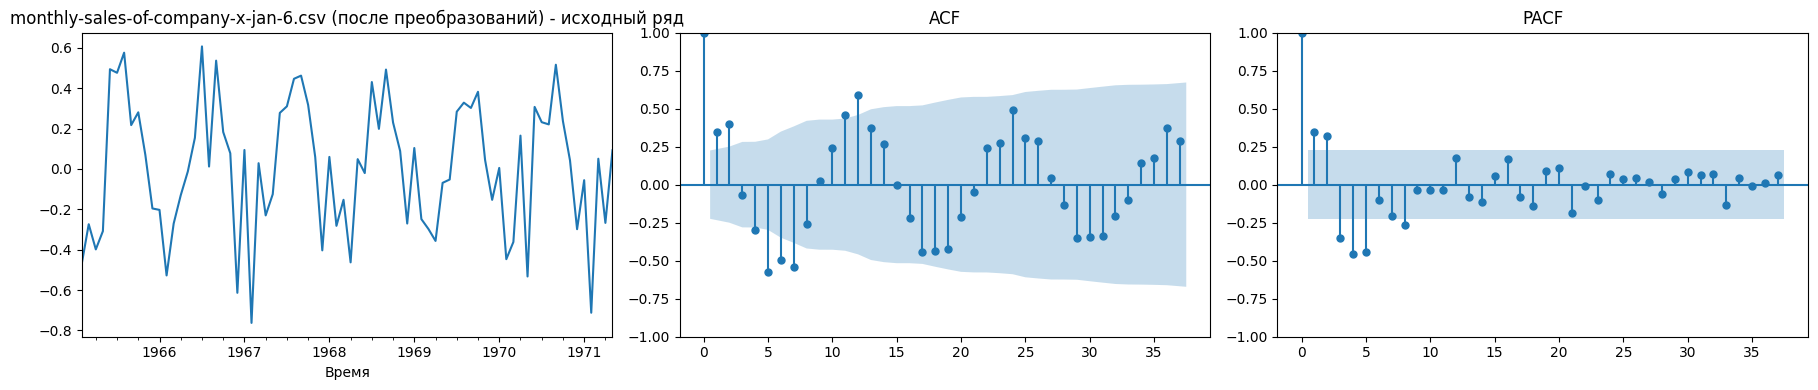


=== Проверка стационарности: После преобразований ===
ADF тест (После преобразований):
  ADF Statistic: -3.1356
  p-value: 0.0240
  Critical values:
    1%: -3.5369
    5%: -2.9079
    10%: -2.5915
  Стационарен (p<0.05): True
KPSS тест (После преобразований):
  KPSS Statistic: 0.0271
  p-value: 0.1000
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): True
✅ Ряд стационарен (по обоим тестам).
✅ Ряд успешно приведён к стационарности.

------------------------------------------------------------

Обработка файла: weekly-closings-of-the-dowjones-.csv
Столбцы в файле: ['Week', 'Close']
Столбец даты: 'Week', столбец значений: 'Close'
Длина ряда: 162


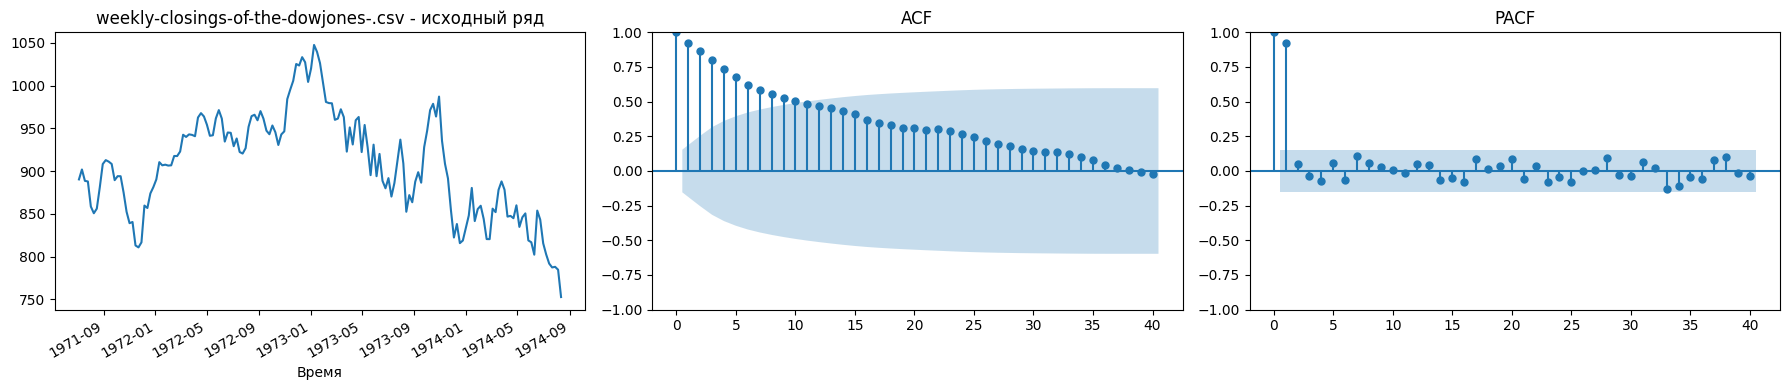


=== Проверка стационарности: Исходный ряд ===
ADF тест (Исходный ряд):
  ADF Statistic: -1.3146
  p-value: 0.6225
  Critical values:
    1%: -3.4716
    5%: -2.8797
    10%: -2.5764
  Стационарен (p<0.05): False
KPSS тест (Исходный ряд):
  KPSS Statistic: 0.5834
  p-value: 0.0241
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): False
❌ Ряд нестационарен (по обоим тестам).

--- Применение преобразований для достижения стационарности ---
  Применено логарифмирование.
  Применено обычное дифференцирование (порядок 1).
Применённые преобразования: ['log', 'diff_1']


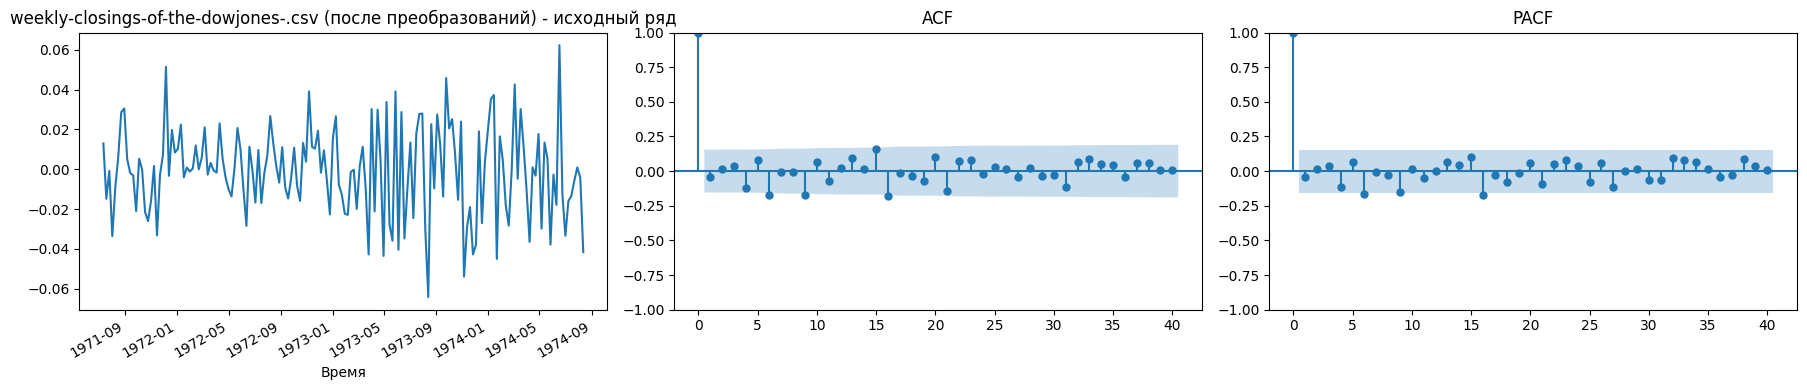


=== Проверка стационарности: После преобразований ===
ADF тест (После преобразований):
  ADF Statistic: -12.9958
  p-value: 0.0000
  Critical values:
    1%: -3.4719
    5%: -2.8798
    10%: -2.5765
  Стационарен (p<0.05): True
KPSS тест (После преобразований):
  KPSS Statistic: 0.1987
  p-value: 0.1000
  Critical values:
    10%: 0.3470
    5%: 0.4630
    2.5%: 0.5740
    1%: 0.7390
  Стационарен (p>0.05): True
✅ Ряд стационарен (по обоим тестам).
✅ Ряд успешно приведён к стационарности.

------------------------------------------------------------

✅ Анализ всех рядов завершён.


In [ ]:
# Основной цикл обработки

import os

if not os.path.exists(FOLDER_PATH):
    print(f'❌ Папка "{FOLDER_PATH}" не найдена. Проверьте путь.')
    print('Пример правильного пути: /content/drive/MyDrive/Series')
else:
    print(f'✅ Папка найдена: {FOLDER_PATH}')

for filename in filenames:
    file_path = os.path.join(FOLDER_PATH, filename)
    if not os.path.exists(file_path):
        print(f'Файл {filename} не найден, пропускаем.')
        continue

    print(f'\n{"="*60}')
    print(f'Обработка файла: {filename}')
    print("="*60)

    df = pd.read_csv(file_path)
    print(f"Столбцы в файле: {df.columns.tolist()}")

    date_col = df.columns[0]
    value_col = df.columns[1]
    print(f"Столбец даты: '{date_col}', столбец значений: '{value_col}'")

    # Парсим даты с помощью нашей функции
    df[date_col] = parse_date_column(df[date_col])
    df = df.set_index(date_col)
    series = df[value_col].astype(float)
    series = series.dropna()
    print(f'Длина ряда: {len(series)}')

    # Визуализация исходного
    plot_series(series, title=filename)

    # Проверка стационарности
    check_stationarity(series, title='Исходный ряд')

    # Определение сезонного периода
    if 'monthly' in filename or 'airline' in filename or 'temperature' in filename or 'robberies' in filename:
        season = 12
    elif 'weekly' in filename:
        season = 52
    elif 'daily' in filename:
        season = 7
    else:
        season = None

    # Логарифмирование для рядов с экспоненциальным ростом
    log_flag = 'passengers' in filename or 'sales' in filename or 'dowjones' in filename

    print('\n--- Применение преобразований для достижения стационарности ---')
    transformed_series, trans_list = make_stationary(series, title=filename,
                                                     season_period=season,
                                                     log_transform=log_flag)
    print(f'Применённые преобразования: {trans_list}')

    # Визуализация после преобразований
    plot_series(transformed_series, title=f'{filename} (после преобразований)')

    # Проверка стационарности после
    is_stationary = check_stationarity(transformed_series, title='После преобразований')
    if is_stationary:
        print('✅ Ряд успешно приведён к стационарности.')
    else:
        print('❌ Ряд всё ещё нестационарен. Возможно, требуется ручная настройка.')

    print("\n" + "-"*60)

print("\n✅ Анализ всех рядов завершён.")